# Task 2: Exploratory Data Analysis on E-Commerce Transaction Data

## Objective
Analyze online retail transaction data to uncover insights about customer behavior, product performance, and sales trends.

## Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

## Load DataSet 

In [2]:
df = pd.read_excel(r"C:\Users\lenovo\Desktop\OutriX_Data_Analytics_Internship\Task_2_ecommerce_eda\OnlineRetail.xlsx")

In [3]:
import os 

print(os.path.exists(r"C:\Users\lenovo\Desktop\OutriX_Data_Analytics_Internship\Task_2_ecommerce_eda\OnlineRetail.xlsx"))

True


In [4]:
import pandas as pd

df = pd.read_excel(
    r"C:\Users\lenovo\Desktop\OutriX_Data_Analytics_Internship\Task_2_ecommerce_eda\OnlineRetail.xlsx",
    engine="openpyxl"
)

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-01-12 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-01-12 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom


In [5]:
df.shape

(541909, 8)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), object(4), str(1)
memory usage: 33.1+ MB


In [7]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [8]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [9]:
df.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-01-12 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-01-12 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-01-12 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-01-12 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-01-12 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-01-12 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-01-12 08:34:00,1.69,13047.0,United Kingdom


## Missing Value Analysis

In [10]:
(df.isnull().sum()/len(df))*100

InvoiceNo       0.000000
StockCode       0.000000
Description     0.268311
Quantity        0.000000
InvoiceDate     0.000000
UnitPrice       0.000000
CustomerID     24.926694
Country         0.000000
dtype: float64

## Duplicate Records

In [11]:
df.duplicated().sum()

np.int64(5268)

In [12]:
## remove
df.drop_duplicates(inplace=True)

In [13]:
## verify
df.duplicated().sum()


np.int64(0)

In [14]:
# convert data 
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

## Revenue Column

In [15]:
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

## Month

In [16]:
df["Month"] = df["InvoiceDate"].dt.month_name()

## Year


In [17]:
df["Year"] = df["InvoiceDate"].dt.year

## Day

In [18]:
df["Day"] = df["InvoiceDate"].dt.day_name()

## Descriptive Statistics

In [19]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID,Revenue,Year
count,536641.000000,536641,536641.000000,401604.000000,536641.000000,536641.000000
mean,9.620029,2011-06-15 21:02:19.959823,4.632656,15281.160818,18.123861,2010.921771
min,-80995.000000,2010-01-12 08:26:00,-11062.060000,12346.000000,-168469.600000,2010.000000
25%,1.000000,2011-03-23 10:27:00,1.250000,13939.000000,3.750000,2011.000000
50%,3.000000,2011-07-03 14:10:00,2.080000,15145.000000,9.870000,2011.000000
75%,10.000000,2011-10-04 15:09:00,4.130000,16784.000000,17.400000,2011.000000
max,80995.000000,2011-12-10 17:19:00,38970.000000,18287.000000,168469.600000,2011.000000
std,219.130156,NaN,97.233118,1714.006089,380.656263,0.268532


## Customer Behavior Analysis

## Total Customer

In [21]:
df["CustomerID"].nunique()

4372

## Top Customers

In [23]:
top_customers = df.groupby("CustomerID")["Revenue"].sum().sort_values(ascending=False).head(10)

Text(0.5, 1.0, 'Top 10 Customers by Revenue')

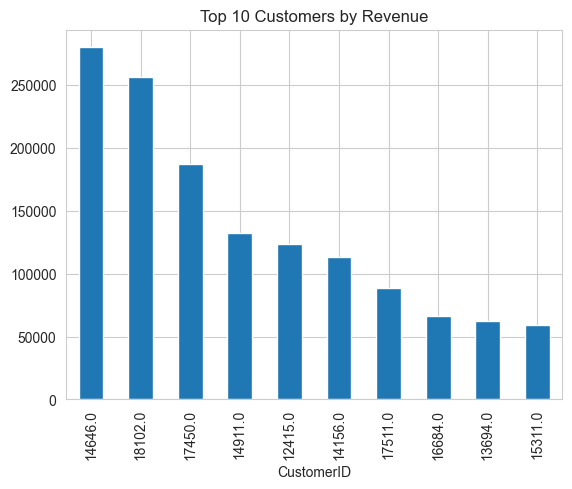

In [24]:
top_customers.plot(kind="bar")
plt.title("Top 10 Customers by Revenue")

## Product Performance Analysis

## Top Selling Product

In [25]:
top_products = df.groupby("Description")["Quantity"].sum().sort_values(ascending=False).head(10)

## Highest Revenue Products

In [26]:
top_revenue = df.groupby("Description")["Revenue"].sum().sort_values(ascending=False).head(10)


## Sales Trend Analysis 

## Monthly Revenue

In [27]:
monthly_sales = df.groupby("Month")["Revenue"].sum()

<Axes: xlabel='Month'>

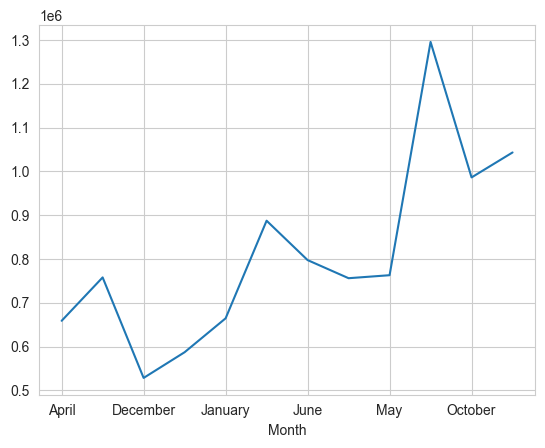

In [28]:
monthly_sales.plot(kind="line")

## Daily Trend

In [29]:
daily_sales = df.groupby("Day")["Revenue"].sum()

## Country Analysis

In [30]:
country_sales = df.groupby("Country")["Revenue"].sum().sort_values(ascending=False).head(10)

<Axes: ylabel='Country'>

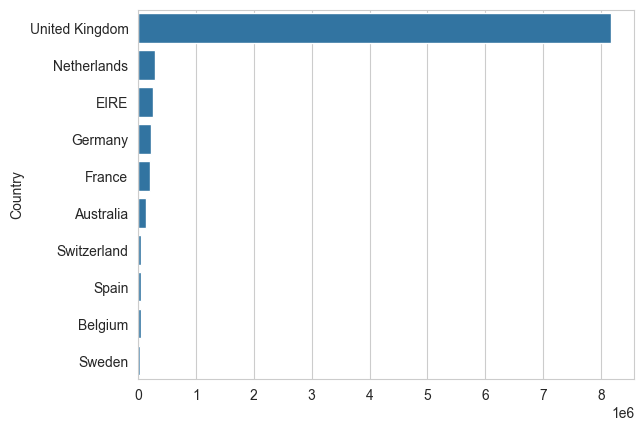

In [31]:
sns.barplot(
    x=country_sales.values,
    y=country_sales.index
)

## Revenue Distribution

Text(0.5, 1.0, 'Revenue Distribution')

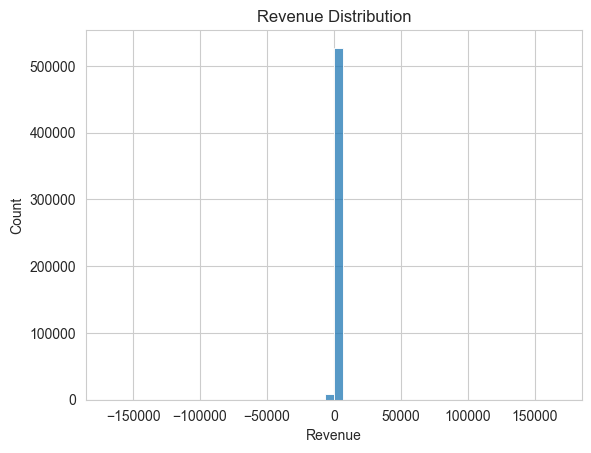

In [32]:
sns.histplot(df["Revenue"], bins=50)
plt.title("Revenue Distribution")

## Correlation Analysis

<Axes: >

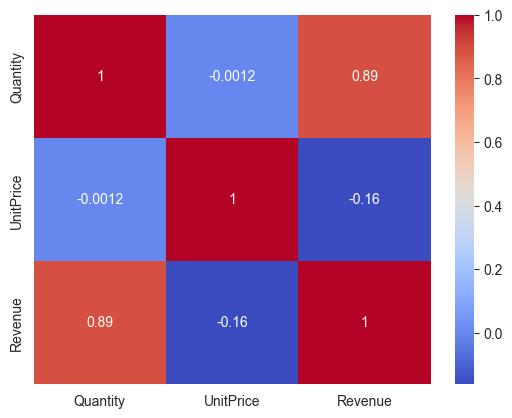

In [33]:
corr = df[["Quantity","UnitPrice","Revenue"]].corr()

sns.heatmap(corr,
            annot=True,
            cmap="coolwarm")

## Outlier Detection

<Axes: xlabel='Quantity'>

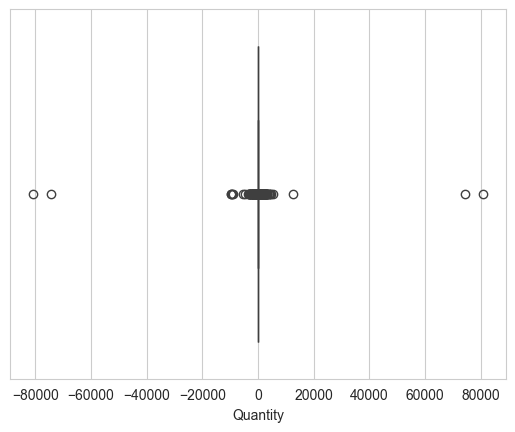

In [34]:
sns.boxplot(x=df["Quantity"])

<Axes: xlabel='UnitPrice'>

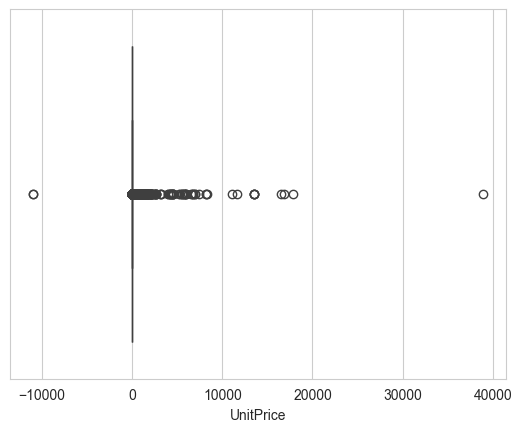

In [35]:
sns.boxplot(x=df["UnitPrice"])